# Importing Libraries

In [33]:
# importing utils library
import copy
import hashlib
import os
import random
import numpy as np
import pandas as pd
from pathlib import Path
from timeit import default_timer as timer
from tqdm.auto import tqdm

# importing data vizs library
import seaborn as sns
from matplotlib import pyplot as plt

# importing sklearn for stratified splitting and metrics.
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# importing torch and vision library.
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.datasets import ImageFolder
from torchvision.transforms import v2
from torchvision.utils import make_grid
from torch.utils.data import DataLoader, Subset
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

# Configuration and reproducibility

* All tunable values live in one cell, so the training notebook and the Streamlit app read the same numbers.
* The values needed at inference time (image size, normalisation, class names, quality-gate thresholds) are saved inside the model artifact at the end of this notebook.

In [34]:
# Central configuration.
seed = 42
dataset_root = os.environ.get(
    "PLANTVILLAGE_PATH",
    "/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color")
artifact_path = Path("plant_disease_mobilenetv3.pt")

# Image preprocessing (ImageNet statistics, fixed constants, nothing is fitted on our data).
resize_size = 256
image_size = 224
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Training.
batch_size = 128
num_workers = 4
epochs = 10
learning_rate = 0.001
patience = 3                # Stop if validation loss does not improve for this many epochs.
train_baseline = True       # Also train the TinyVGG baseline (compared on validation only).
check_duplicates = True     # Remove byte-identical images that appear across splits.

In [35]:
# Checking cuda availability and assigning to variable device.
def check_gpu_availability():
    """Verifying if environment has GPU or not.
    """
    if torch.cuda.is_available():
        return torch.device("cuda")
    else:
        return torch.device("cpu")


def set_seed(seed_value: int = 42) -> None:
    """Seed every random number generator used in this notebook.

    Args:
        seed_value (int): The seed to apply. Defaults to 42.
    """
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    torch.cuda.manual_seed_all(seed_value)


def seed_worker(worker_id: int) -> None:
    """Seed numpy and random inside each DataLoader worker so augmentation is reproducible."""
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


device = check_gpu_availability()
set_seed(seed)
print(f"Device available: {device}")

Device available: cuda


# Dataset importation and preprocessing

* Created a function to check and load PlantVillage Dataset
* Preprocess dataset using transform v2
* Split the dataset into train, validation, and test using a **stratified** split
* Removed byte-identical images that appear in more than one split

In [36]:
# Loading dataset and adding error catch
def load_plantvillage(file_path: str | Path) -> Path:
    """Checking and Outputing Dataset from Path.
    This function check if a path exist, convert it to str or path and output it.

    Args:
        file_path(str | Path): PlantVillage dataset path
    Returns:
        Path: A pathlib pointing to a verifiable directory.
    Raises:
        FileNotFoundError: if the directory does not exist.
        NotADirectoryError: if the path exists but is not a directory.
    """
    # Convert str input back to Path.
    path_obj = Path(file_path)

    if not path_obj.exists():
        raise FileNotFoundError(f"Error! The folder '{file_path}' does not exist..")
    if not path_obj.is_dir():
        raise NotADirectoryError(f"Error! '{file_path}' is not a directory..")

    print(f"PlantVillage Dataset: {path_obj}")
    return path_obj


dataset_path = load_plantvillage(dataset_root)

PlantVillage Dataset: /kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color


**Data Augmentation for training data.**

Preprocessing steps used: -
 * RandomResizedCrop
 * Random Horizontal/Vertical Flip
 * ColorJitter
 * RandomRotation

In [37]:
# Data Augmentation on training dataset for crop disease.
train_transforms = v2.Compose([
    # Random Resized Crop (224*224)
    v2.RandomResizedCrop(size=(image_size, image_size), scale=(0.8, 1.0),
                         ratio=(0.75, 1.33)),

    # Flips images as orientation varies
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomVerticalFlip(p=0.5),

    # Adding Color Jitter
    v2.ColorJitter(brightness=0.2,
                   contrast=0.2,
                   saturation=0.1,
                   hue=0.04),
    # Rotating images
    v2.RandomRotation(degrees=15),
    # Convert to a Tensor object
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),

    # Normalize the scaled float tensor
    v2.Normalize(mean=imagenet_mean, std=imagenet_std)
])

**Preprocessing for validation and test data**

Validation and test images get **no random augmentation**, so the scores are deterministic and measured on unmodified images.
They still go through the same resize, crop and normalisation as training.
This is a measurement choice, not a data-leakage safeguard. Leakage is controlled in the splitting step below.

The shorter side is resized to 256 (instead of squashing to 256x256), so non-square photos from the app are not distorted.
For the square PlantVillage images the result is identical to the previous version.
The same pipeline is reused in `app.py`.

In [38]:
# Deterministic preprocessing for validation, test and inference.
val_transforms = v2.Compose([
    # Resize the shorter side slightly larger first (keeps aspect ratio)
    v2.Resize(size=resize_size, antialias=True),
    # Crop the center 224x224
    v2.CenterCrop(size=(image_size, image_size)),
    # Convert to a Tensor object
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),

    # Normalize the scaled float tensor
    v2.Normalize(mean=imagenet_mean, std=imagenet_std)
])

In [39]:
# Scan the folder ONCE to obtain samples, labels and classes.
train_dataset_base = ImageFolder(root=dataset_path, transform=train_transforms)
class_names = train_dataset_base.classes
num_classes = len(class_names)

# Shallow copy shares the file list but carries a different transform (no second disk scan).
val_dataset_base = copy.copy(train_dataset_base)
val_dataset_base.transform = val_transforms

print(f"Number of classes: {num_classes}")
print(class_names)

# Class balance check (the classes are strongly imbalanced).
class_counts = pd.Series(train_dataset_base.targets).value_counts().sort_index()
print(f"Images per class: min={class_counts.min()} | max={class_counts.max()}")

Number of classes: 38
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite

In [40]:
def split_indices(targets: list[int],
                  train_size: float = 0.70,
                  val_size: float = 0.15,
                  seed_value: int = 42):
    """Create a stratified train/validation/test split of dataset indices.

    Every class keeps (approximately) the same proportion in each split, so rare
    classes are not missing from validation or test by chance.

    Args:
        targets (list[int]): Class label of every sample in the dataset.
        train_size (float): Fraction used for training. Defaults to 0.70.
        val_size (float): Fraction used for validation. Defaults to 0.15.
            The remainder (1 - train_size - val_size) is used for testing.
        seed_value (int): Random state for reproducibility.
    Returns:
        tuple[list[int], list[int], list[int]]: train, validation and test indices.
    """
    targets = np.asarray(targets)
    all_indices = np.arange(len(targets))

    train_idx, holdout_idx = train_test_split(
        all_indices, train_size=train_size,
        stratify=targets, random_state=seed_value)

    # Share of the hold-out part that becomes validation (the rest is test).
    val_share = val_size / (1 - train_size)
    val_idx, test_idx = train_test_split(
        holdout_idx, train_size=val_share,
        stratify=targets[holdout_idx], random_state=seed_value)

    # Splits must never overlap.
    assert not (set(train_idx) & set(val_idx)), "Train/validation overlap"
    assert not (set(train_idx) & set(test_idx)), "Train/test overlap"
    assert not (set(val_idx) & set(test_idx)), "Validation/test overlap"

    return train_idx.tolist(), val_idx.tolist(), test_idx.tolist()


train_indices, val_indices, test_indices = split_indices(
    train_dataset_base.targets, train_size=0.70, val_size=0.15, seed_value=seed)
print(f"Before duplicate check -> train: {len(train_indices)} | "
      f"val: {len(val_indices)} | test: {len(test_indices)}")

Before duplicate check -> train: 38013 | val: 8145 | test: 8147


In [41]:
# def hash_file(path: str | Path, chunk_size: int = 1 << 20) -> str:
#     """Return the MD5 digest of a file's bytes (used only to detect identical files)."""
#     digest = hashlib.md5(usedforsecurity=False)
#     with open(path, "rb") as file:
#         for chunk in iter(lambda: file.read(chunk_size), b""):
#             digest.update(chunk)
#     return digest.hexdigest()


# def remove_cross_split_duplicates(samples: list, train_idx: list[int],
#                                   val_idx: list[int], test_idx: list[int]):
#     """Drop validation/test images whose bytes also appear in an earlier split.

#     Priority is train > validation > test, so training data is never touched.
#     Only byte-identical files are caught. Flipped, rotated or re-photographed copies
#     of the same leaf are NOT detected by this check (see the notes in the review).

#     Args:
#         samples (list): ImageFolder.samples, a list of (path, label) tuples.
#         train_idx, val_idx, test_idx (list[int]): Split indices.
#     Returns:
#         tuple: cleaned (val_idx, test_idx) and the number of removed images per split.
#     """
#     hashes = {i: hash_file(samples[i][0])
#               for i in tqdm(train_idx + val_idx + test_idx, desc="Hashing images")}

#     train_hashes = {hashes[i] for i in train_idx}
#     clean_val = [i for i in val_idx if hashes[i] not in train_hashes]

#     seen_hashes = train_hashes | {hashes[i] for i in val_idx}
#     clean_test = [i for i in test_idx if hashes[i] not in seen_hashes]

#     removed = {"val": len(val_idx) - len(clean_val),
#                "test": len(test_idx) - len(clean_test)}
#     return clean_val, clean_test, removed


# if check_duplicates:
#     val_indices, test_indices, removed = remove_cross_split_duplicates(
#         train_dataset_base.samples, train_indices, val_indices, test_indices)
#     print(f"Duplicates removed from validation: {removed['val']} | test: {removed['test']}")

# print(f"Final split -> train: {len(train_indices)} | "
#       f"val: {len(val_indices)} | test: {len(test_indices)}")

In [42]:
# Wrap the indices around the correct base dataset instance
# Train gets the train transform
train_subset = Subset(train_dataset_base, train_indices)

# Validation and Test get the deterministic transform
val_subset = Subset(val_dataset_base, val_indices)
test_subset = Subset(val_dataset_base, test_indices)


def build_dataloader(dataset: torch.utils.data.Dataset, shuffle: bool = False) -> DataLoader:
    """Create a DataLoader with the notebook-wide settings.

    Args:
        dataset (torch.utils.data.Dataset): The dataset (subset) to load.
        shuffle (bool): Shuffle every epoch. True for training only.
    Returns:
        DataLoader: A reproducible loader (seeded generator and workers).
    """
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=num_workers,
        pin_memory=(device.type == "cuda"),
        persistent_workers=(num_workers > 0),
        worker_init_fn=seed_worker,
        generator=generator
    )


# Creating your DataLoaders
train_loader = build_dataloader(train_subset, shuffle=True)
val_loader = build_dataloader(val_subset)
test_loader = build_dataloader(test_subset)

In [43]:
# Displaying the total number of images in each subset
print(f"Total training images: {len(train_subset)}")
print(f"Total validation images: {len(val_subset)}")
print(f"Total test images: {len(test_subset)}\n")

# Extract a single batch from the training loader to check the shape
train_images, train_labels = next(iter(train_loader))
print(f"Train batch shape: {train_images.shape}")

# Every class must appear in every split.
for split_name, split_subset in [("train", train_subset), ("val", val_subset), ("test", test_subset)]:
    split_labels = [train_dataset_base.targets[i] for i in split_subset.indices]
    print(f"Classes in {split_name}: {len(set(split_labels))}/{num_classes}")

Total training images: 38013
Total validation images: 8145
Total test images: 8147

Train batch shape: torch.Size([128, 3, 224, 224])
Classes in train: 38/38
Classes in val: 38/38
Classes in test: 38/38


# Displaying the PlantVillage images

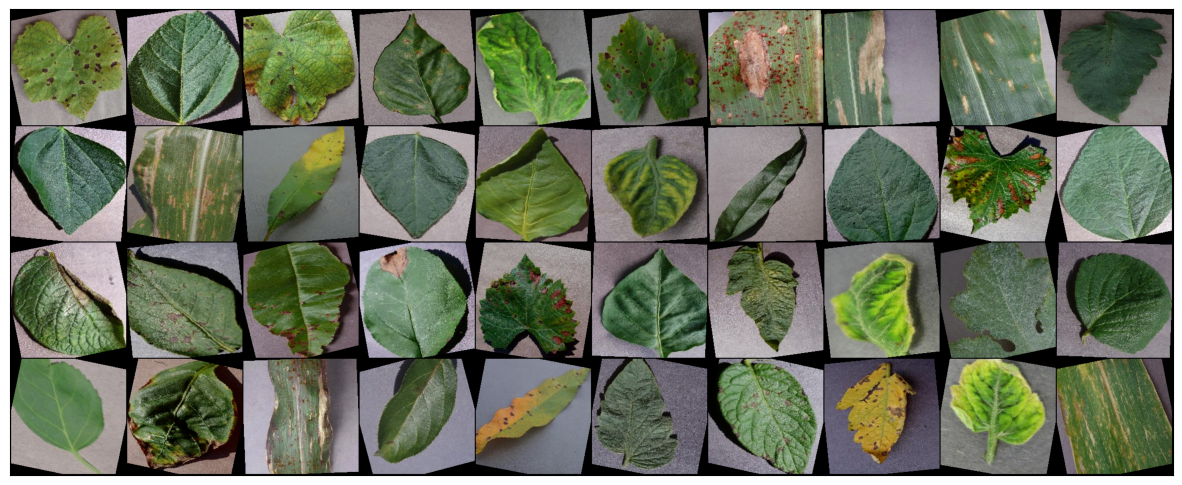

In [44]:
def denormalize(images: torch.Tensor,
                mean: list[float] = imagenet_mean,
                std: list[float] = imagenet_std) -> torch.Tensor:
    """Undo Normalize so a tensor is back in the [0, 1] range for display or quality checks.

    Args:
        images (torch.Tensor): Normalized tensor of shape [B, 3, H, W] or [3, H, W].
        mean (list[float]): Mean used for normalisation.
        std (list[float]): Standard deviation used for normalisation.
    Returns:
        torch.Tensor: Tensor with values clamped to [0, 1].
    """
    mean_t = torch.tensor(mean, device=images.device).view(-1, 1, 1)
    std_t = torch.tensor(std, device=images.device).view(-1, 1, 1)
    return (images * std_t + mean_t).clamp(0, 1)


# displaying plant images using make_grid.
def show_batch(dl: DataLoader, max_images: int = 40):
    """Show the first images of one batch (de-normalised so colours are correct)."""
    images, labels = next(iter(dl))
    fig, ax = plt.subplots(figsize=(15, 8))
    ax.set_xticks([]); ax.set_yticks([])
    ax.imshow(make_grid(denormalize(images[:max_images]), nrow=10).permute(1, 2, 0))
    plt.show()


show_batch(train_loader)

# Training utilities

In [45]:
# Calculate accuracy (a classification metric)
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item() # torch.eq() calculates where two tensors are equal
    acc = (correct / len(y_pred)) * 100
    return acc


# Calculate the training time on either GPU or CPU
def print_train_time(start: float, end: float, device: torch.device | None = None):
    """Prints difference between start and end time.

    Args:
        start (float): Start time of computation (preferred in timeit format).
        end (float): End time of computation.
        device (torch.device, optional): Device that compute is running on. Defaults to None.
    Returns:
        float: time between start and end in seconds (higher is longer).
    """
    total_time = end - start
    print(f"Train time on {device}: {total_time:.3f} seconds")
    return total_time


def count_parameters(model: torch.nn.Module):
    """Return (total, trainable) parameter counts."""
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

In [46]:
# define func for training model.
def train_step(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               accuracy_fn,
               device: torch.device = device,
               frozen_module: torch.nn.Module | None = None):
    """A function for training our model for one epoch.

    Args:
        model (torch.nn.Module): A PyTorch model for making predictions on training data.
        data_loader (torch.utils.data.DataLoader): The target dataset to predict on.
        loss_fn (torch.nn.Module): The loss function of model.
        optimizer (torch.optim.Optimizer): The optimizer that updates the trainable weights.
        accuracy_fn: An accuracy function to compare the models predictions to the truth labels.
        device (torch.device): Device the computation runs on.
        frozen_module (torch.nn.Module, optional): A frozen part of the model (e.g. the
            pretrained backbone). It is kept in eval mode so its BatchNorm running
            statistics are not silently updated while its weights are frozen.
    Returns:
        tuple[float, float]: Average training loss and accuracy (%) per sample.
    """
    train_loss, train_acc = 0, 0
    # Move model to device either (GPU or CPU)
    model.to(device)
    # Set model to training mode
    model.train()
    if frozen_module is not None:
        frozen_module.eval()

    for X, y in data_loader:
        # Send data to GPU with non_blocking=True for pinned memory speedups
        X, y = X.to(device, non_blocking=True), y.to(device, non_blocking=True)

        # Forward pass
        y_pred = model(X)

        # Calculate loss (weighted by batch size so the smaller last batch is not over-counted)
        loss = loss_fn(y_pred, y)
        train_loss += loss.item() * len(y)
        train_acc += accuracy_fn(y_true=y,
                                 y_pred=y_pred.argmax(dim=1)) * len(y) # Go from logits -> pred labels

        # Optimizer zero grad
        optimizer.zero_grad()
        # Loss backward
        loss.backward()
        # Optimizer step
        optimizer.step()

    # Return calculated loss and accuracy per sample.
    num_samples = len(data_loader.dataset)
    return train_loss / num_samples, train_acc / num_samples


def collect_predictions(model: torch.nn.Module,
                        data_loader: torch.utils.data.DataLoader,
                        loss_fn: torch.nn.Module,
                        device: torch.device = device):
    """Run the model over a loader without gradients.

    Args:
        model (torch.nn.Module): A PyTorch model capable of making predictions on data_loader.
        data_loader (torch.utils.data.DataLoader): The target dataset to predict on.
        loss_fn (torch.nn.Module): The loss function of model.
        device (torch.device): Device the computation runs on.
    Returns:
        tuple: average loss per sample, true labels (np.ndarray), predicted labels (np.ndarray).
    """
    total_loss = 0
    all_true, all_pred = [], []
    model.to(device)

    # put model in eval mode
    model.eval()
    # Turn on inference context manager
    with torch.inference_mode():
        for X, y in data_loader:
            X, y = X.to(device, non_blocking=True), y.to(device, non_blocking=True)
            logits = model(X)
            total_loss += loss_fn(logits, y).item() * len(y)
            all_true.append(y.cpu())
            all_pred.append(logits.argmax(dim=1).cpu()) # Go from logits -> pred labels

    y_true = torch.cat(all_true)
    y_pred = torch.cat(all_pred)
    return total_loss / len(y_true), y_true, y_pred


# define func for validating model.
def val_step(data_loader: torch.utils.data.DataLoader,
             model: torch.nn.Module,
             loss_fn: torch.nn.Module,
             accuracy_fn,
             device: torch.device = device):
    """A function for validation our model.

    Args:
        data_loader (torch.utils.data.DataLoader): The target dataset to predict on.
        model (torch.nn.Module): A PyTorch model capable of making predictions on data_loader.
        loss_fn (torch.nn.Module): The loss function of model.
        accuracy_fn: An accuracy function to compare the models predictions to the truth labels.
        device (torch.device): Device the computation runs on.
    Returns:
        tuple[float, float]: Average validation loss and accuracy (%) per sample.
    """
    val_loss, y_true, y_pred = collect_predictions(model, data_loader, loss_fn, device)
    val_acc = accuracy_fn(y_true=y_true, y_pred=y_pred)
    return val_loss, val_acc


def eval_model(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               accuracy_fn,
               device: torch.device = device):
    """Returns a dictionary containing the results of model predicting on data_loader.

    Args:
        model (torch.nn.Module): A PyTorch model capable of making predictions on data_loader.
        data_loader (torch.utils.data.DataLoader): The target dataset to predict on.
        loss_fn (torch.nn.Module): The loss function of model.
        accuracy_fn: An accuracy function to compare the models predictions to the truth labels.
        device (torch.device): Device the computation runs on.
    Returns:
        (dict): Loss, accuracy, macro-F1 and the raw labels/predictions for further analysis.
    """
    loss, y_true, y_pred = collect_predictions(model, data_loader, loss_fn, device)
    return {"model_name": model.__class__.__name__, # only works when model was created with a class
            "model_loss": loss,
            "model_acc": accuracy_fn(y_true=y_true, y_pred=y_pred),
            # Macro-F1 gives every class equal weight, accuracy alone hides weak rare classes.
            "model_macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
            "y_true": y_true.numpy(),
            "y_pred": y_pred.numpy()}

In [47]:
def fit(model: torch.nn.Module,
        train_loader: torch.utils.data.DataLoader,
        val_loader: torch.utils.data.DataLoader,
        loss_fn: torch.nn.Module,
        optimizer: torch.optim.Optimizer,
        accuracy_fn,
        epochs: int,
        device: torch.device = device,
        frozen_module: torch.nn.Module | None = None,
        patience: int | None = None):
    """Train for several epochs, keep the best weights (lowest validation loss) and restore them.

    Only the validation set is used for checkpoint selection and early stopping.
    The test set is never touched here.

    Args:
        model (torch.nn.Module): Model to train.
        train_loader, val_loader (DataLoader): Training and validation loaders.
        loss_fn (torch.nn.Module): The loss function.
        optimizer (torch.optim.Optimizer): The optimizer.
        accuracy_fn: Accuracy function (percent).
        epochs (int): Maximum number of epochs.
        device (torch.device): Device the computation runs on.
        frozen_module (torch.nn.Module, optional): Frozen part kept in eval mode.
        patience (int, optional): Stop after this many epochs without improvement.
    Returns:
        list[dict]: Per-epoch metrics (train_loss, train_acc, val_loss, val_acc).
    """
    history = []
    best_val_loss = float("inf")
    best_state, best_epoch, stale_epochs = None, 0, 0

    for epoch in tqdm(range(epochs)):
        print(f"Epoch: {epoch}\n---------")

        # Running training step
        train_loss, train_acc = train_step(
            model=model, data_loader=train_loader, loss_fn=loss_fn,
            optimizer=optimizer, accuracy_fn=accuracy_fn,
            device=device, frozen_module=frozen_module)
        print(f"Train loss: {train_loss:.5f} | Train accuracy: {train_acc:.2f}%")

        # Running validation steps
        val_loss, val_acc = val_step(
            data_loader=val_loader, model=model, loss_fn=loss_fn,
            accuracy_fn=accuracy_fn, device=device)
        print(f"Validation loss: {val_loss:.5f} | Validation accuracy: {val_acc:.2f}%\n")

        # Save metrics to history for plotting functions
        history.append({
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc
        })

        # Keep the best checkpoint by validation loss.
        if val_loss < best_val_loss:
            best_val_loss, best_epoch, stale_epochs = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            stale_epochs += 1
            if patience is not None and stale_epochs >= patience:
                print(f"Early stopping at epoch {epoch} (best epoch: {best_epoch}).")
                break

    model.load_state_dict(best_state)
    print(f"Restored best weights from epoch {best_epoch} (val loss {best_val_loss:.5f}).")
    return history


def plot_accuracies(history_log):
    plt.figure()
    plt.plot([x["train_acc"] for x in history_log], "-bx")
    plt.plot([x["val_acc"] for x in history_log], "-rx")
    plt.xlabel("epoch")
    plt.ylabel("accuracy (%)")
    plt.legend(["Training", "Validation"])
    plt.title("Accuracy vs. No. of epochs")
    plt.show()


def plot_losses(history_log):
    plt.figure()
    plt.plot([x["train_loss"] for x in history_log], "-bx")
    plt.plot([x["val_loss"] for x in history_log], "-rx")
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.legend(["Training", "Validation"])
    plt.title("Loss vs. No. of epochs")
    plt.show()

# Manual model development (baseline)

The baseline is trained for comparison only. It is compared with the pretrained model on the **validation** set; the test set is reserved for the single final evaluation of the model we ship.

TinyVGG parameters: 694,406 (694,406 trainable)


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 0
---------


Train loss: 3.44736 | Train accuracy: 12.24%
Validation loss: 3.24042 | Validation accuracy: 15.00%

Epoch: 1
---------
Train loss: 3.01150 | Train accuracy: 21.18%
Validation loss: 2.95031 | Validation accuracy: 19.86%

Epoch: 2
---------
Train loss: 2.75193 | Train accuracy: 25.21%
Validation loss: 2.69597 | Validation accuracy: 26.03%

Epoch: 3
---------
Train loss: 2.56912 | Train accuracy: 29.45%
Validation loss: 2.38896 | Validation accuracy: 33.17%

Epoch: 4
---------
Train loss: 2.32179 | Train accuracy: 35.25%
Validation loss: 2.27426 | Validation accuracy: 33.70%

Epoch: 5
---------
Train loss: 2.03005 | Train accuracy: 42.53%
Validation loss: 1.78524 | Validation accuracy: 49.44%

Epoch: 6
---------
Train loss: 1.82082 | Train accuracy: 47.31%
Validation loss: 1.60295 | Validation accuracy: 54.30%

Epoch: 7
---------
Train loss: 1.66686 | Train accuracy: 51.29%
Validation loss: 1.50987 | Validation accuracy: 55.80%

Epoch: 8
---------
Train loss: 1.54929 | Train accuracy: 54

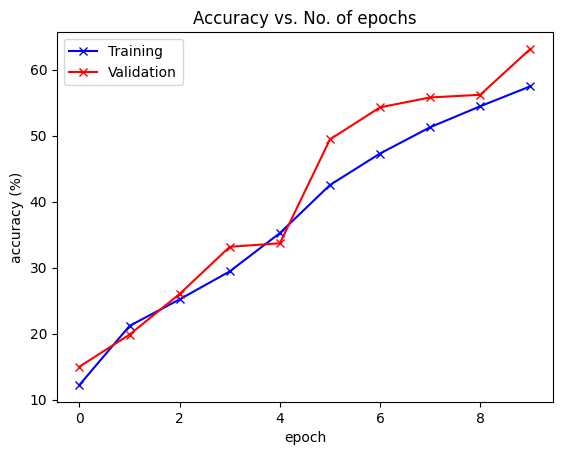

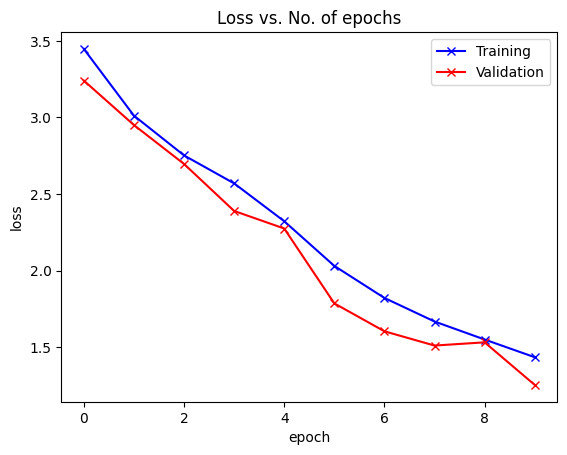

In [48]:
class TinyVGGClassifier(nn.Module):
    """Small VGG-style CNN used as a baseline.

    Args:
        num_classes (int): Number of output classes.
    """
    def __init__(self, num_classes: int):
        super().__init__()
        # Sequential Conv2d layer. Extracts low-level features (H*W*C)
        self.block_1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3,
                      stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3,
                      stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block_2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3,
                      stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 32, kernel_size=3,
                      stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Forcing the spatial dimensions to 4x4 before flattening
        self.pool = nn.AdaptiveAvgPool2d((4, 4))

        # Flattening input and pass fully connected layers
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32*4*4, 1024),
            nn.ReLU(),
            nn.Linear(1024, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Pass input through feature extraction blocks
        x = self.block_1(x)
        x = self.block_2(x)
        # Dimension reduction
        x = self.pool(x)
        # Flatten and classify
        x = self.classifier(x)
        return x


loss_fn = nn.CrossEntropyLoss()

if train_baseline:
    # Set seed for reproducibility
    set_seed(seed)
    model_2 = TinyVGGClassifier(num_classes=num_classes).to(device)
    total_params, trainable_params = count_parameters(model_2)
    print(f"TinyVGG parameters: {total_params:,} ({trainable_params:,} trainable)")

    optimizer = torch.optim.SGD(params=model_2.parameters(), lr=0.01)

    # Measure time
    train_time_start_model_2 = timer()
    history_model_2 = fit(
        model=model_2, train_loader=train_loader, val_loader=val_loader,
        loss_fn=loss_fn, optimizer=optimizer, accuracy_fn=accuracy_fn,
        epochs=epochs, device=device, patience=patience)
    train_time_end_model_2 = timer()
    total_train_time_model_2 = print_train_time(
        start=train_time_start_model_2,
        end=train_time_end_model_2,
        device=device)

    plot_accuracies(history_model_2)
    plot_losses(history_model_2)

# Pretrained model: MobileNetV3 Small (transfer learning)

* Backbone (`features`) is frozen, only the new classifier head is trained.
* The frozen backbone is kept in eval mode during training so its BatchNorm statistics are not changed.

In [49]:
def build_mobilenet_classifier(num_classes: int,
                               pretrained: bool = True,
                               freeze_backbone: bool = True,
                               dropout: float = 0.2) -> nn.Module:
    """Build MobileNetV3-Small with a new classification head.

    Args:
        num_classes (int): One output unit for each class.
        pretrained (bool): Load ImageNet weights (needs internet). Use False when the
            weights will be loaded from our own checkpoint (e.g. in the Streamlit app).
        freeze_backbone (bool): Freeze all layers in the "features" section (requires_grad=False).
        dropout (float): Dropout probability before the final linear layer.
    Returns:
        nn.Module: The MobileNetV3-Small model.
    """
    weights = MobileNet_V3_Small_Weights.DEFAULT if pretrained else None
    model = mobilenet_v3_small(weights=weights)

    if freeze_backbone:
        for param in model.features.parameters():
            param.requires_grad = False

    # Read the input size from the original head instead of hard-coding 576.
    in_features = model.classifier[0].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(p=dropout, inplace=True),
        nn.Linear(in_features=in_features, out_features=num_classes, bias=True))
    return model


# Set the manual seeds (head initialisation is reproducible)
set_seed(seed)
mobilenet_model = build_mobilenet_classifier(num_classes=num_classes).to(device)

total_params, trainable_params = count_parameters(mobilenet_model)
print(f"MobileNetV3-Small parameters: {total_params:,} ({trainable_params:,} trainable)")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 96.4MB/s]

MobileNetV3-Small parameters: 948,934 (21,926 trainable)


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 0
---------
Train loss: 1.24586 | Train accuracy: 72.32%
Validation loss: 0.57780 | Validation accuracy: 87.46%

Epoch: 1
---------
Train loss: 0.50151 | Train accuracy: 88.61%
Validation loss: 0.37870 | Validation accuracy: 90.82%

Epoch: 2
---------
Train loss: 0.37490 | Train accuracy: 90.76%
Validation loss: 0.29894 | Validation accuracy: 92.29%

Epoch: 3
---------
Train loss: 0.31385 | Train accuracy: 92.02%
Validation loss: 0.26354 | Validation accuracy: 92.90%

Epoch: 4
---------
Train loss: 0.27571 | Train accuracy: 92.71%
Validation loss: 0.22887 | Validation accuracy: 93.73%

Epoch: 5
---------
Train loss: 0.25478 | Train accuracy: 93.12%
Validation loss: 0.21880 | Validation accuracy: 93.76%

Epoch: 6
---------
Train loss: 0.23578 | Train accuracy: 93.59%
Validation loss: 0.20178 | Validation accuracy: 94.11%

Epoch: 7
---------
Train loss: 0.22194 | Train accuracy: 93.71%
Validation loss: 0.18855 | Validation accuracy: 94.75%

Epoch: 8
---------
Train loss: 0.21038 |

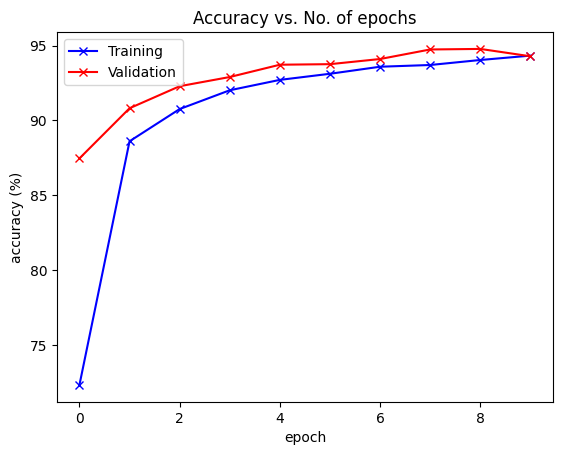

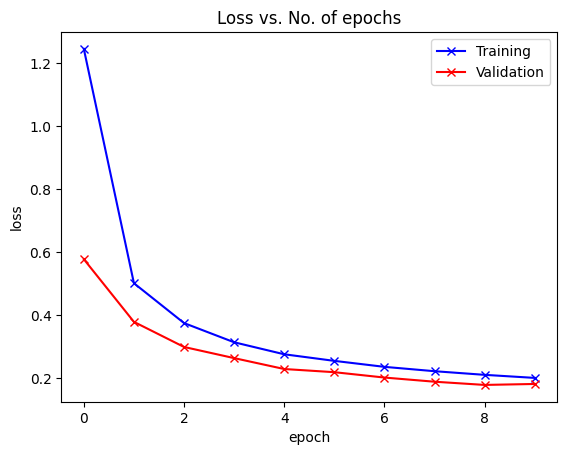

In [50]:
# Define loss and optimizer (only the parameters that are actually trained)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    [p for p in mobilenet_model.parameters() if p.requires_grad],
    lr=learning_rate)

# Set seed for reproducity
set_seed(seed)

# Measure time
train_time_start_mobilenet = timer()
history_mobilenet = fit(
    model=mobilenet_model, train_loader=train_loader, val_loader=val_loader,
    loss_fn=loss_fn, optimizer=optimizer, accuracy_fn=accuracy_fn,
    epochs=epochs, device=device,
    frozen_module=mobilenet_model.features, patience=patience)
train_time_end_mobilenet = timer()
total_train_time_mobilenet = print_train_time(
    start=train_time_start_mobilenet,
    end=train_time_end_mobilenet,
    device=device)

plot_accuracies(history_mobilenet)
plot_losses(history_mobilenet)

**Model selection on the validation set only**

In [51]:
# Compare candidates on VALIDATION data. The test set is not used to choose a model.
val_results = {}
if train_baseline:
    val_results["TinyVGGClassifier"] = eval_model(model_2, val_loader, loss_fn, accuracy_fn, device)
val_results["MobileNetV3Small"] = eval_model(mobilenet_model, val_loader, loss_fn, accuracy_fn, device)

val_table = pd.DataFrame({
    name: {"val_loss": r["model_loss"], "val_acc": r["model_acc"], "val_macro_f1": r["model_macro_f1"]}
    for name, r in val_results.items()
}).T
print(val_table.round(4))

                   val_loss  val_acc  val_macro_f1
TinyVGGClassifier    1.2527  63.1553        0.5099
MobileNetV3Small     0.1784  94.7821        0.9344


# Image quality gate

The gate rejects photos that are too dark, over-exposed, blurry, low-contrast or without visible leaf, **before** they reach the classifier.

Important: the gate must receive images in the **[0, 1]** range, not normalised tensors. The data loaders return normalised tensors, so they are passed through `denormalize` first.
Thresholds should be tuned on the **validation** set and reported on the test set.

In [52]:
# Image quality checker.
class ImageQualityGate:
    """Rule-based photo quality check.

    Args:
        min_brightness, max_brightness (float): Accepted mean grayscale range (0-1).
        min_contrast (float): Minimum grayscale standard deviation.
        min_blur_score (float): Minimum variance of the Laplacian (sharpness).
        min_leaf_fraction (float): Minimum share of green (vegetation) pixels.
    """
    def __init__(
        self,
        min_brightness=0.12,
        max_brightness=0.92,
        min_contrast=0.05,
        min_blur_score=0.002,
        min_leaf_fraction=0.08,
    ):
        self.min_brightness = min_brightness
        self.max_brightness = max_brightness
        self.min_contrast = min_contrast
        self.min_blur_score = min_blur_score
        self.min_leaf_fraction = min_leaf_fraction

        # Laplacian kernel for blur detection
        self.laplacian_kernel = torch.tensor(
            [[0., 1., 0.],
             [1., -4., 1.],
             [0., 1., 0.]]
        ).view(1, 1, 3, 3)

    def to_dict(self) -> dict:
        """Thresholds as plain numbers, so they can be saved inside the model artifact."""
        return {
            "min_brightness": self.min_brightness,
            "max_brightness": self.max_brightness,
            "min_contrast": self.min_contrast,
            "min_blur_score": self.min_blur_score,
            "min_leaf_fraction": self.min_leaf_fraction,
        }

    @torch.inference_mode()
    def assess(self, images):
        """
        images: float tensor [B, 3, H, W], RGB values in range [0, 1]

        Returns:
            accepted: Boolean tensor [B]
            metrics: Dictionary of per-image quality measures
        """
        if images.ndim != 4 or images.shape[1] != 3:
            raise ValueError(f"Expected a [B, 3, H, W] tensor, got {tuple(images.shape)}")

        device = images.device
        kernel = self.laplacian_kernel.to(device)

        red = images[:, 0]
        green = images[:, 1]
        blue = images[:, 2]

        # 1. Brightness and contrast
        grayscale = (
            0.299 * red +
            0.587 * green +
            0.114 * blue
        )

        brightness = grayscale.mean(dim=(1, 2))
        contrast = grayscale.std(dim=(1, 2))

        # 2. Blur: variance of Laplacian.
        # Low variance means few sharp edges, often indicating blur.
        laplacian = F.conv2d(
            grayscale.unsqueeze(1),
            kernel,
            padding=1
        )
        blur_score = laplacian.var(dim=(1, 2, 3))

        # 3. Approximate leaf coverage.
        # Excess Green: useful for detecting visibly green vegetation.
        excess_green = 2 * green - red - blue
        leaf_mask = excess_green > 0.08
        leaf_fraction = leaf_mask.float().mean(dim=(1, 2))

        brightness_ok = (
            (brightness >= self.min_brightness) &
            (brightness <= self.max_brightness)
        )
        contrast_ok = contrast >= self.min_contrast
        sharp_enough = blur_score >= self.min_blur_score
        leaf_visible = leaf_fraction >= self.min_leaf_fraction

        accepted = (
            brightness_ok &
            contrast_ok &
            sharp_enough &
            leaf_visible
        )

        metrics = {
            "brightness": brightness,
            "contrast": contrast,
            "blur_score": blur_score,
            "leaf_fraction": leaf_fraction,
            "brightness_ok": brightness_ok,
            "contrast_ok": contrast_ok,
            "sharp_enough": sharp_enough,
            "leaf_visible": leaf_visible,
        }

        return accepted, metrics

    def get_feedback(self, metrics: dict, index: int = 0) -> list[str]:
        """Turn the failed checks of one image into messages a farmer can act on.

        Args:
            metrics (dict): The metrics dictionary returned by assess().
            index (int): Position of the image inside the batch.
        Returns:
            list[str]: One message per failed check (empty when the image passed).
        """
        messages = []

        if not metrics["brightness_ok"][index].item():
            if metrics["brightness"][index].item() < self.min_brightness:
                messages.append("The photo is too dark. Move to a brighter area.")
            else:
                messages.append("The photo is over-exposed. Avoid strong glare or direct sun.")
        if not metrics["contrast_ok"][index].item():
            messages.append("The photo has very low contrast. Use a plain background.")
        if not metrics["sharp_enough"][index].item():
            messages.append("Hold the phone steady and make sure the leaf is in focus.")
        if not metrics["leaf_visible"][index].item():
            messages.append("Place one affected leaf clearly in the centre of the photo.")

        return messages


quality_gate = ImageQualityGate()

In [53]:
def evaluate_with_gate(model: torch.nn.Module,
                       data_loader: torch.utils.data.DataLoader,
                       gate: ImageQualityGate,
                       device: torch.device = device) -> pd.DataFrame:
    """Run the gate and the model on every image of a loader and collect per-image records.

    The gate gets de-normalised [0, 1] images. All images are classified (even rejected
    ones) so we can measure how accuracy differs between accepted and rejected photos.

    Returns:
        pd.DataFrame: One row per image with label, prediction, accepted flag and quality metrics.
    """
    model.to(device)
    model.eval()
    records = []

    for X, y in data_loader:
        X, y = X.to(device, non_blocking=True), y.to(device, non_blocking=True)

        accepted, metrics = gate.assess(denormalize(X))
        with torch.inference_mode():
            preds = model(X).argmax(dim=1)

        records.append(pd.DataFrame({
            "label": y.cpu().numpy(),
            "pred": preds.cpu().numpy(),
            "accepted": accepted.cpu().numpy(),
            "brightness": metrics["brightness"].cpu().numpy(),
            "contrast": metrics["contrast"].cpu().numpy(),
            "blur_score": metrics["blur_score"].cpu().numpy(),
            "leaf_fraction": metrics["leaf_fraction"].cpu().numpy(),
        }))

    return pd.concat(records, ignore_index=True)


def summarise_gate(results: pd.DataFrame, class_names: list[str]) -> None:
    """Print rejection rate, accuracy on accepted vs rejected photos, and the most-rejected classes."""
    correct = results["label"] == results["pred"]
    print(f"Rejected: {(~results['accepted']).mean() * 100:.2f}% of {len(results)} images")
    print(f"Accuracy on accepted: {correct[results['accepted']].mean() * 100:.2f}%")
    if (~results["accepted"]).any():
        print(f"Accuracy on rejected: {correct[~results['accepted']].mean() * 100:.2f}%")

    # A gate that rejects mostly diseased leaves (yellow/brown, little green) would hide the
    # very cases the app exists for, so check the rejection rate per class.
    rejection_by_class = (~results["accepted"]).groupby(results["label"]).mean() * 100
    rejection_by_class.index = [class_names[i] for i in rejection_by_class.index]
    print("\nMost-rejected classes (%):")
    print(rejection_by_class.sort_values(ascending=False).head(10).round(1))


# Tune/inspect thresholds on VALIDATION data.
val_gate_results = evaluate_with_gate(mobilenet_model, val_loader, quality_gate, device)
summarise_gate(val_gate_results, class_names)

Rejected: 0.60% of 8145 images
Accuracy on accepted: 94.81%
Accuracy on rejected: 89.80%

Most-rejected classes (%):
Cherry_(including_sour)___Powdery_mildew    8.2
Tomato___Late_blight                        3.1
Orange___Haunglongbing_(Citrus_greening)    2.3
Strawberry___Leaf_scorch                    1.2
Tomato___Early_blight                       0.7
Corn_(maize)___healthy                      0.6
Corn_(maize)___Common_rust_                 0.6
Apple___healthy                             0.4
Squash___Powdery_mildew                     0.4
Tomato___Tomato_Yellow_Leaf_Curl_Virus      0.1
Name: accepted, dtype: float64


# Final test evaluation (run once)

The test set is used here **once**, for the model that will be shipped.

In [54]:
# Get final test results for the selected model.
mobilenet_test_results = eval_model(
    model=mobilenet_model.to(device),
    data_loader=test_loader,
    loss_fn=loss_fn,
    accuracy_fn=accuracy_fn,
    device=device
)
print(f"Test loss: {mobilenet_test_results['model_loss']:.4f} | "
      f"Test accuracy: {mobilenet_test_results['model_acc']:.2f}% | "
      f"Test macro-F1: {mobilenet_test_results['model_macro_f1']:.4f}")

print(classification_report(
    mobilenet_test_results["y_true"], mobilenet_test_results["y_pred"],
    target_names=class_names, digits=3, zero_division=0))

Test loss: 0.1765 | Test accuracy: 94.91% | Test macro-F1: 0.9354
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.815     0.936     0.871        94
                                 Apple___Black_rot      1.000     1.000     1.000        93
                          Apple___Cedar_apple_rust      1.000     0.902     0.949        41
                                   Apple___healthy      0.960     0.980     0.970       247
                               Blueberry___healthy      0.991     0.987     0.989       226
          Cherry_(including_sour)___Powdery_mildew      0.994     0.975     0.984       158
                 Cherry_(including_sour)___healthy      0.977     0.977     0.977       128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.934     0.740     0.826        77
                       Corn_(maize)___Common_rust_      0.983     0.978     0.980       179
             

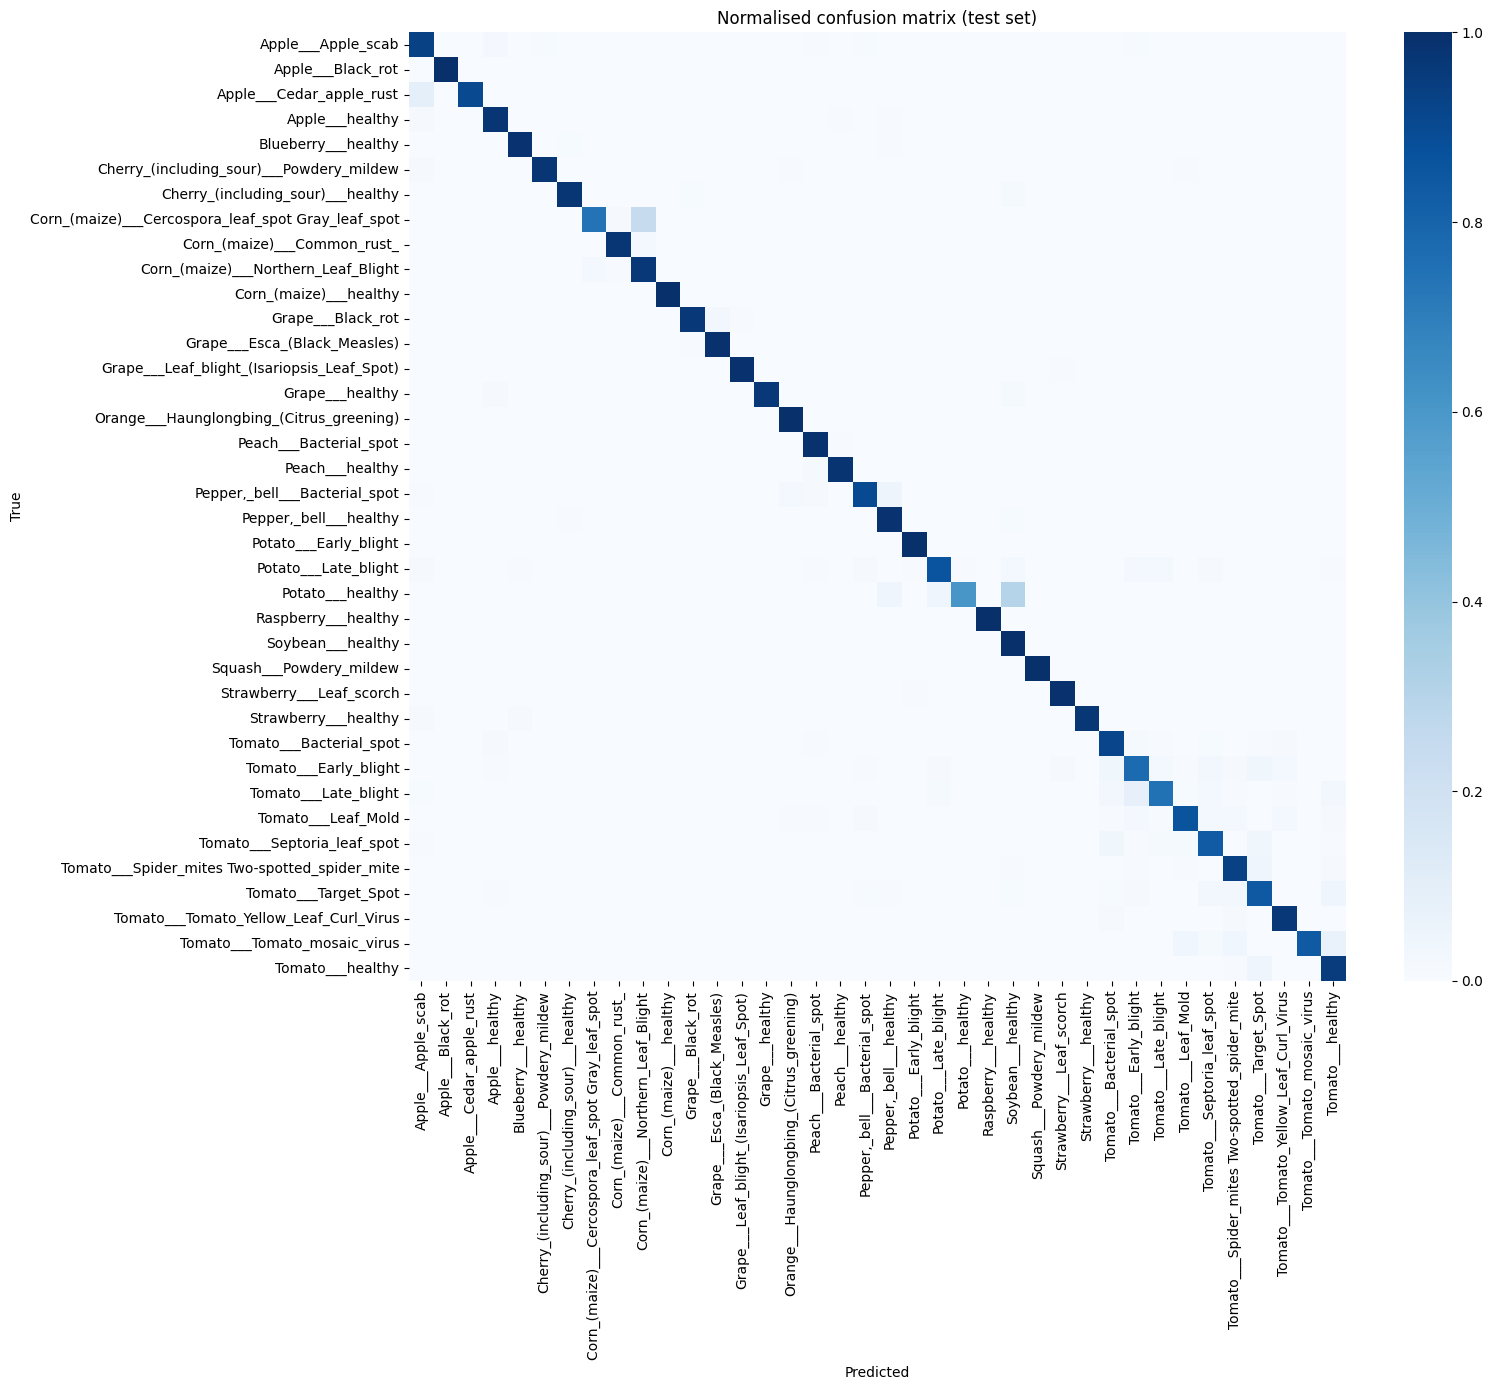

Rejected: 0.77% of 8147 images
Accuracy on accepted: 94.94%
Accuracy on rejected: 90.48%

Most-rejected classes (%):
Cherry_(including_sour)___Powdery_mildew    7.0
Tomato___Late_blight                        5.6
Corn_(maize)___Northern_Leaf_Blight         3.4
Orange___Haunglongbing_(Citrus_greening)    3.0
Potato___Late_blight                        1.3
Corn_(maize)___healthy                      1.1
Strawberry___Leaf_scorch                    0.6
Soybean___healthy                           0.1
Blueberry___healthy                         0.0
Apple___Black_rot                           0.0
Name: accepted, dtype: float64


In [55]:
# Confusion matrix (row-normalised) to see which diseases are confused with each other.
cm = confusion_matrix(mobilenet_test_results["y_true"], mobilenet_test_results["y_pred"],
                      labels=range(num_classes), normalize="true")
plt.figure(figsize=(16, 14))
sns.heatmap(cm, xticklabels=class_names, yticklabels=class_names, cmap="Blues", cbar=True)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Normalised confusion matrix (test set)")
plt.tight_layout()
plt.show()

# Gate behaviour on the test set (thresholds were inspected on validation only).
test_gate_results = evaluate_with_gate(mobilenet_model, test_loader, quality_gate, device)
summarise_gate(test_gate_results, class_names)

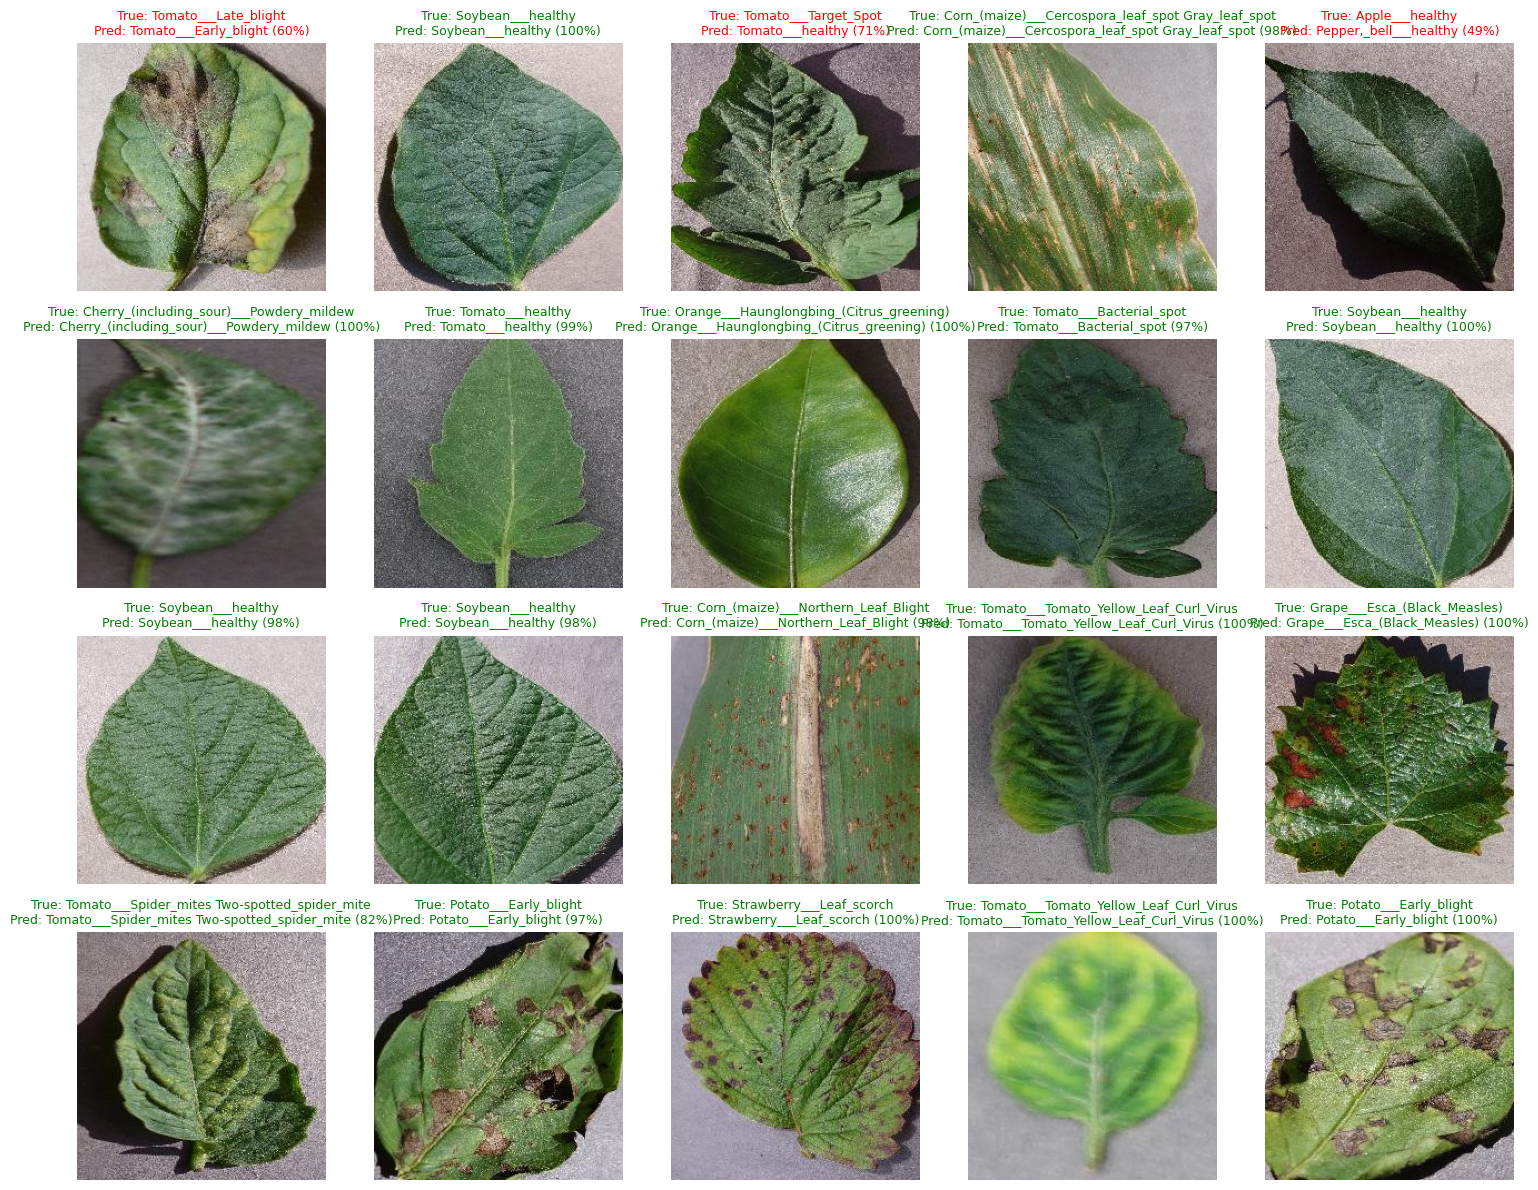

In [56]:
# Predicting images.
def predict_image(img: torch.Tensor, model: torch.nn.Module,
                  device_target: torch.device, class_names: list[str]):
    """Predict the class of one preprocessed image tensor.

    Args:
        img (torch.Tensor): Normalized image tensor [3, H, W].
        model (torch.nn.Module): Trained classifier.
        device_target (torch.device): Device to run on.
        class_names (list[str]): Class names in training order.
    Returns:
        tuple[str, float]: Predicted class name and its softmax probability.
    """
    # Convert single image tensor to a batch format: [1, C, H, W]
    xb = img.unsqueeze(0).to(device_target)
    model.eval()
    with torch.inference_mode():
        probabilities = torch.softmax(model(xb), dim=1)
    # Pick index with highest probability
    confidence, pred_idx = probabilities.max(dim=1)
    return class_names[pred_idx.item()], confidence.item()


def show_predictions(model: torch.nn.Module, subset: Subset,
                     class_names: list[str], device_target: torch.device, num_images: int = 20):
    """Plot the first images of a subset with true and predicted labels."""
    # Setup the grid plot (4 rows, 5 columns = 20 images)
    fig, axes = plt.subplots(4, 5, figsize=(15, 12))
    axes = axes.flatten()

    # Looping through the first images of the subset.
    for i in range(min(num_images, len(axes))):
        img, label = subset[i]

        # Run prediction
        predicted_class, confidence = predict_image(img, model, device_target, class_names)
        true_class = class_names[label]

        ax = axes[i]
        ax.imshow(denormalize(img).permute(1, 2, 0))
        ax.axis("off")

        title_color = "green" if predicted_class == true_class else "red"
        ax.set_title(f"True: {true_class}\nPred: {predicted_class} ({confidence:.0%})",
                     color=title_color, fontsize=9)

    plt.tight_layout()
    plt.show()


show_predictions(mobilenet_model, test_subset, class_names, device)

# Export the model artifact for deployment

The artifact stores the weights **and** everything the app needs to reproduce preprocessing: class names, image size, normalisation constants and gate thresholds.
It contains only tensors and plain Python types, so the app can load it with `torch.load(..., weights_only=True)` (no arbitrary pickle code is executed).

In [ ]:
def save_artifact(model: torch.nn.Module, path: Path) -> None:
    """Save weights and inference settings in a single checkpoint file.

    Args:
        model (torch.nn.Module): The trained model.
        path (Path): Destination file.
    """
    artifact = {
        "model_state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
        "architecture": "mobilenet_v3_small",
        "class_names": class_names,
        "resize_size": resize_size,
        "image_size": image_size,
        "mean": imagenet_mean,
        "std": imagenet_std,
        "quality_gate": quality_gate.to_dict(),
        "test_accuracy": float(mobilenet_test_results["model_acc"]),
        "test_macro_f1": float(mobilenet_test_results["model_macro_f1"]),
        "torch_version": str(torch.__version__),
        "seed": seed,
    }
    torch.save(artifact, path)
    print(f"Saved artifact: {path} ({path.stat().st_size / 1e6:.1f} MB)")


save_artifact(mobilenet_model, artifact_path)

# Sanity check: reload on CPU exactly as the app will, and confirm identical predictions.
reloaded = torch.load(artifact_path, map_location="cpu", weights_only=True)
check_model = build_mobilenet_classifier(len(reloaded["class_names"]), pretrained=False, freeze_backbone=False)
check_model.load_state_dict(reloaded["model_state_dict"])
check_model.eval()

sample_images, _ = next(iter(test_loader))
with torch.inference_mode():
    original_logits = mobilenet_model.to("cpu").eval()(sample_images[:8])
    reloaded_logits = check_model(sample_images[:8])
print("Reloaded model matches:", torch.allclose(original_logits, reloaded_logits, atol=1e-5))
mobilenet_model.to(device);

Saved artifact: plant_disease_mobilenetv3.pt (3.9 MB)
Reloaded model matches: True
